In [1]:
import sys
sys.path.append('..')

In [2]:
from src import utils
from src import linear_RNN
import numpy as np
from types import SimpleNamespace
import neurogym as ngym
import matplotlib.pyplot as plt
import copy

In [3]:
def multisensory_integration_continuous(args, mean=True): 
    dataset = ngym.Dataset('MultiSensoryIntegration-v0', batch_size=args.num_samples, 
        seq_len=args.trajectory_length+1, env_kwargs = {'timing': {
            'fixation': 0,
            'stimulus': int((args.trajectory_length)*100),
            'delay': 0,
            'decision': 100}})
    inputs, labels = dataset()
 
    inputs = inputs[:-1,:,1:] # remove decision-time input and fixation input
    inputs = inputs.transpose(1,0,2) # batch_size, traj_len, input_size
    
    if args.single_output_y:
        if mean:
            labels = np.mean(inputs, axis=1)
        else:
            labels = np.sum(inputs, axis=1)
        labels = labels.reshape(args.num_samples, 1, args.output_size)
     
    return inputs, labels

In [4]:
def test(X, y, W_x, W_h, W_y, args): 
    if args.single_output_y:
        y_hat = np.zeros((args.num_samples, 1, args.output_size))
    else:
        y_hat = np.zeros((args.num_samples, args.trajectory_length, args.output_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", W_h, h_t) + np.einsum("ij,bj->bi", W_x, X[:,t])
        if args.nonlinear_RNN:
            h_t = F.relu(h_t)
        y_t = np.einsum("ij,bj->bi", W_y, h_t)
        if not args.single_output_y:
            y_hat[:,t] = y_t
    if args.single_output_y:
        y_hat = y_t.reshape(y_t.shape[0], 1, -1)
        
    loss = (1/2)*np.mean((y-y_hat)**2)

    return loss

In [5]:
def extrapolation_test_performance(args, tape, traj_length, mean):
    new_args = copy.deepcopy(args)
    new_args.trajectory_length = traj_length
    X, y = multisensory_integration_continuous(new_args, mean)
    test_loss = np.zeros((int(args.num_epochs/args.log_every_e_epoch)))
    for e in range(int(args.num_epochs/args.log_every_e_epoch)):
        test_loss[e] = test(X,y,tape.W_x[0,e], tape.W_h[0,e], tape.W_y[0,e], new_args)
    return test_loss

In [6]:
sum_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'neuro',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 4,
    'num_samples' : 1000,
    'num_epochs' : 50000, 
    'lr' : 0.1,
    'initialization_scale' : 1e-1,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant'],
    'delta' : [1,0], 
    'lambda_0' : [1,0],
    'S_T' : [1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.16, 0.16, 0.16, 0.16],
    'in_mode_init' : [0.4, 0.4, 0.4, 0.4],
    'out_mode_init': [0.4, 0.4, 0.4, 0.4],
    'rec_mode_init': [0.4, 0.4, 0.4, 0.4],
    'num_SV' : 4,
    'aligned_student_weights': False, 
    'log_H': True,
    'log_y_hat': True,
    'compute_NTK': False,
    'nonlinear_RNN': False, 
    'log_every_e_epoch': 100, 
    'subsample_NTK': False,
    'eigenspace_dynamics': False,
    'subsample_H': True,
    'theta': None
}
sum_args = SimpleNamespace(**sum_args)

In [7]:
sum_data_tape = utils.get_data_tape(sum_args)
sum_tape = utils.get_tape_module(sum_args)
seed = 0
utils.set_seeds(seed)
sum_X, sum_y = multisensory_integration_continuous(sum_args, mean=False)
sum_data_tape.X[seed] = sum_X
sum_data_tape.y[seed] = sum_y

# unaligned
sum_tape = utils.initialize_unaligned_student(sum_args, seed, sum_tape)

sum_model = linear_RNN.LinearRNN_multiseed(sum_args, sum_tape, seed)
sum_model.train(sum_data_tape.X[seed], sum_data_tape.y[seed]) 
sum_model.project_SVD_space(sum_data_tape)
sum_tape = sum_model.tape

/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/gymnasium/envs/registration.py:481: UserWarning: WARN: The environment creator metadata doesn't include `render_modes`, contains: ['description', 'paper_link', 'paper_name', 'tags']
  logger.warn(
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/gymnasium/core.py:311: UserWarning: WARN: env.seed to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrapped.seed` for environment variables or `env.get_wrapper_attr('seed')` that will search the reminding wrappers.
  logger.warn(
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/gymnasium/core.py:311: UserWarning: WARN: env.new_trial to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrapped.new_trial` for environment variables or `env.get_wrapper_attr('new_trial')` that will search the reminding wrappe

In [8]:
mean_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'neuro',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 4,
    'num_samples' : 1000,
    'num_epochs' : 250000, 
    'lr' : 0.1,
    'initialization_scale' : 1e-1,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant'],
    'delta' : [1,0], 
    'lambda_0' : [1,0],
    'S_T' : [1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.16, 0.16, 0.16, 0.16],
    'in_mode_init' : [0.4, 0.4, 0.4, 0.4],
    'out_mode_init': [0.4, 0.4, 0.4, 0.4],
    'rec_mode_init': [0.4, 0.4, 0.4, 0.4],
    'num_SV' : 4,
    'aligned_student_weights': False, #True, #False,
    'log_H': True,
    'log_y_hat': True,
    'compute_NTK': False,
    'nonlinear_RNN': False, 
    'log_every_e_epoch': 100, #1,
    'subsample_NTK': False,
    'eigenspace_dynamics': False,
    'subsample_H': True,
    'theta': None
}
mean_args = SimpleNamespace(**mean_args)

In [9]:
mean_data_tape = utils.get_data_tape(mean_args)
mean_tape = utils.get_tape_module(mean_args)
seed = 0
utils.set_seeds(seed)
mean_X, mean_y = multisensory_integration_continuous(mean_args, mean=True)
mean_data_tape.X[seed] = mean_X
mean_data_tape.y[seed] = mean_y

# unaligned
mean_tape = utils.initialize_unaligned_student(mean_args, seed, mean_tape)

mean_model = linear_RNN.LinearRNN_multiseed(mean_args, mean_tape, seed)
mean_model.train(mean_data_tape.X[seed], mean_data_tape.y[seed]) 
mean_model.project_SVD_space(mean_data_tape)
mean_tape = mean_model.tape

In [10]:
mean_test_loss_100 = extrapolation_test_performance(mean_args, mean_tape, 100, True)
sum_test_loss_100 = extrapolation_test_performance(sum_args, sum_tape, 100, False)

mean_test_loss_50 = extrapolation_test_performance(mean_args, mean_tape, 50, True)
sum_test_loss_50 = extrapolation_test_performance(sum_args, sum_tape, 50, False)

mean_test_loss_75 = extrapolation_test_performance(mean_args, mean_tape, 75, True)
sum_test_loss_75 = extrapolation_test_performance(sum_args, sum_tape, 75, False)

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_19663/705205594.py:7: ComplexWarning: Casting complex values to real discards the imaginary part
  test_loss[e] = test(X,y,tape.W_x[0,e], tape.W_h[0,e], tape.W_y[0,e], new_args)


In [12]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_19663/2069023470.py:18: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


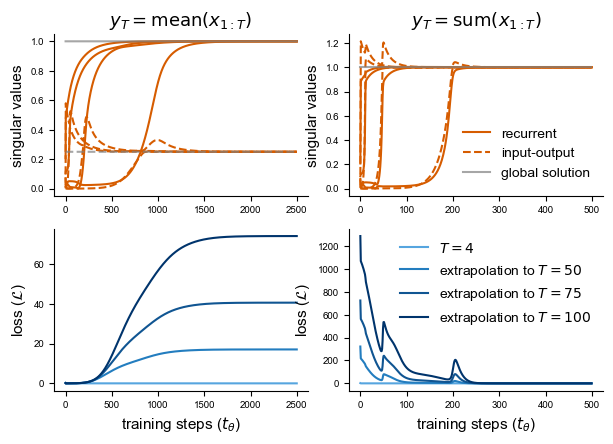

In [13]:
fig = plt.figure(figsize=(6,4), layout='constrained') # 5x4
mosaic = """
ab
cd
"""

# SV learning for mean & sum
# loss & extrapolation test loss

    
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])
    
fig.tight_layout()
        
axd['a'].plot(mean_tape.recurrent_modes[0], color=blind_colors[0], label='recurrent')
axd['a'].plot(mean_tape.input_output_modes[0], color=blind_colors[0], ls='dashed', label='input-output')
axd['a'].plot([1.0]*2500, color='gray', alpha=0.7, label='global solution')
axd['a'].plot([0.25]*2500, color='gray', alpha=0.7, ls='dashed', label='global solution')
axd['a'].set_ylabel(r'singular values',fontsize=11)
axd['a'].set_title(r'$y_T=\text{mean}(x_{1:T})$',fontsize=13)

axd['b'].plot(sum_tape.recurrent_modes[0], color=blind_colors[0], label='recurrent')
axd['b'].plot(sum_tape.input_output_modes[0], color=blind_colors[0], ls='dashed', label='input-output')
axd['b'].set_ylabel(r'singular values',fontsize=11)
axd['b'].set_title(r'$y_T=\text{sum}(x_{1:T})$',fontsize=13)
axd['b'].plot([1.0]*500, color='gray', alpha=0.7, label='global solution')
handles, labels = axd['b'].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axd['b'].legend(by_label.values(), by_label.keys(),frameon=False,bbox_to_anchor=(1,0.5),fontsize=10)

axd['c'].plot(mean_tape.loss[seed], color=div_cmap.colors[29], label=r'$T=4$')
axd['c'].plot(mean_test_loss_50, color=div_cmap.colors[19], label=r'extrapolation to $T=50$')
axd['c'].plot(mean_test_loss_75, color=div_cmap.colors[9], label=r'extrapolation to $T=75$')
axd['c'].plot(mean_test_loss_100, color=div_cmap.colors[0], label=r'extrapolation to $T=100$')
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)',fontsize=11)
axd['c'].set_xlabel(r'training steps ($t_\theta$)',fontsize=11)
axd['d'].plot(sum_tape.loss[seed], color=div_cmap.colors[29], label=r'$T=4$')
axd['d'].plot(sum_test_loss_50, color=div_cmap.colors[19], label=r'extrapolation to $T=50$')
axd['d'].plot(sum_test_loss_75, color=div_cmap.colors[9], label=r'extrapolation to $T=75$')
axd['d'].plot(sum_test_loss_100, color=div_cmap.colors[0], label=r'extrapolation to $T=100$')
axd['d'].set_ylabel(r'loss ($\mathcal{L}$)',fontsize=11)
axd['d'].set_xlabel(r'training steps ($t_\theta$)',fontsize=11)
axd['d'].legend(frameon=False,fontsize=10)

# fig.savefig('paper_figs/sensory_integration.svg', dpi=300, transparent=True,bbox_inches='tight')
# fig.savefig('paper_figs/sensory_integration.png', dpi=300, transparent=True,bbox_inches='tight')
# fig.savefig('paper_figs/sensory_integration.pdf', dpi=300, transparent=True,bbox_inches='tight')